# BrushCue Example: Tilt Shift

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/tilt_shift.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/tilt-shift

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


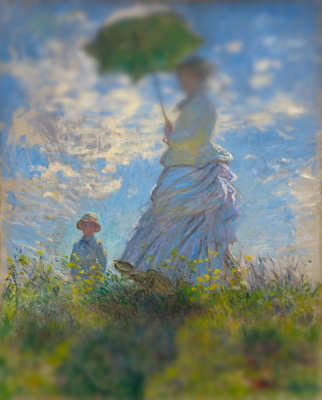

In [1]:
import io
from PIL import Image

import brushcue as bc

focus_position = 0.55
focus_width = 0.2
transition = 0.25
blur_sigma = 14.0
saturation = 1.3
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
vivid = input_image.saturation_adjust(saturation)
blurred = vivid.gaussian_blur(blur_sigma).crop(input_bounds)
graph = vivid.spacial_effect_shader(
    "let height = image_bounds.w - image_bounds.y;\nlet center_y = image_bounds.y + focus_position * height;\nlet half_band = focus_width * height * 0.5;\nlet ramp = max(transition * height, 1.0);\nlet d = abs(position.y - center_y);\nlet amount = smoothstep(half_band, half_band + ramp, d);\nlet sharp = sample(position);\nlet blurred = sampleBlurred(position);\nlet blurred_rgb = blurred.rgb;\nreturn vec4<f32>(mix(sharp.rgb, blurred_rgb, amount), sharp.a);",
    "",
    0.0,
    bc.Dictionary.create()
    .add("focus_position", focus_position)
    .add("focus_width", focus_width)
    .add("transition", transition)
    .add("image_bounds", input_bounds)
    .add("blurred", blurred),
    bc.ColorRepresentation.srgb(),
).crop(input_bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
